C:\Users\Jam Villanueva\AppData\Local\Temp\ipykernel_21544\395046849.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Estimator_Team', y='Prediction_Error', ax=axes[0], palette='Set2')
C:\Users\Jam Villanueva\AppData\Local\Temp\ipykernel_21544\395046849.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Primary_Vendor', y='Prediction_Error', ax=axes[1], palette='Set3')


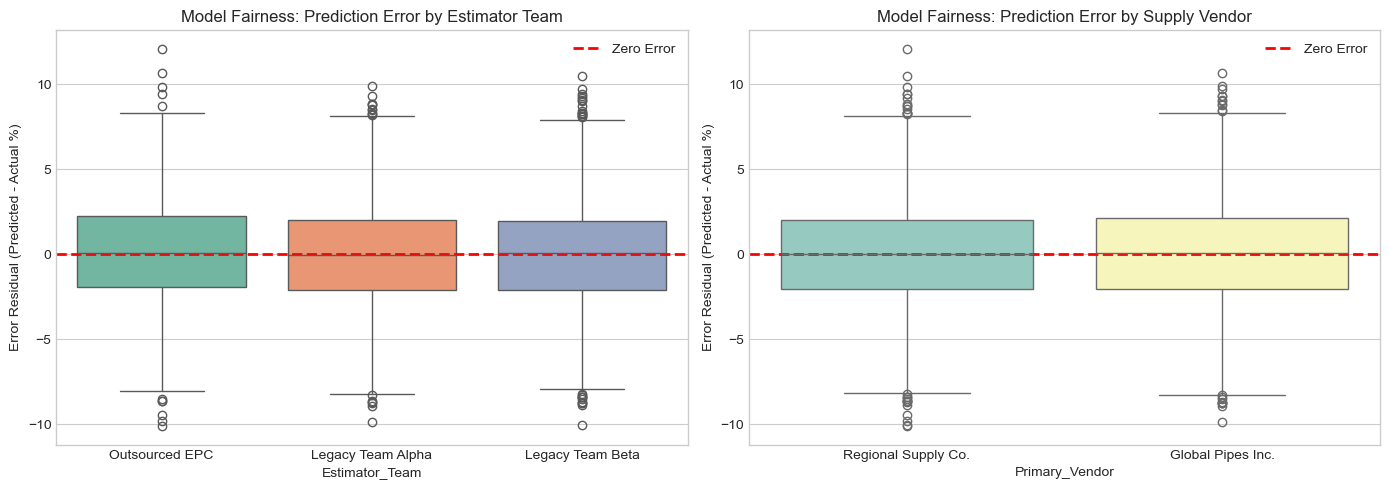

 98%|===================| 8347/8500 [00:59<00:01]        

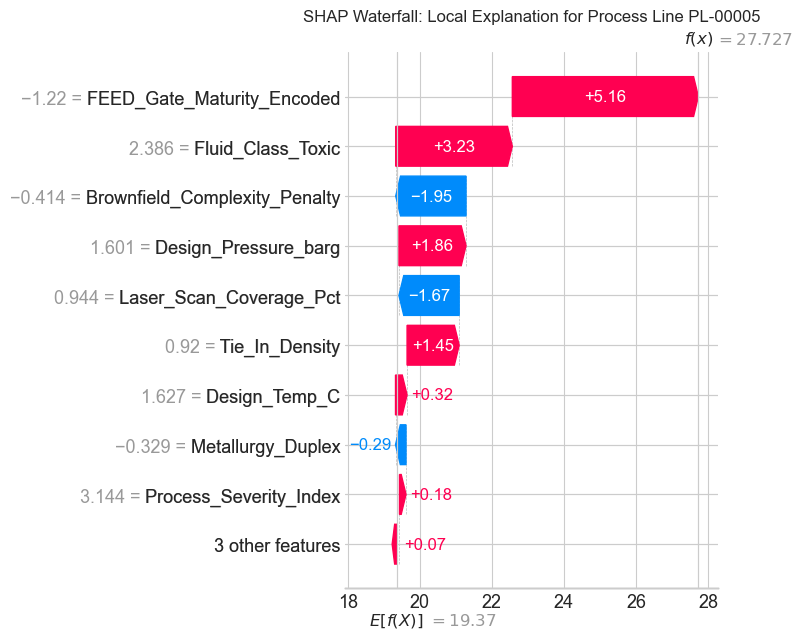

In [2]:
import os
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')

# 1. Define Paths and Load Data
base_path = r"C:\Users\Jam Villanueva\Documents\AIM PGD AIML\1_Capstone Project"
data_path = os.path.join(base_path, "data", "synthetic_brownfield_mto_data.csv")
models_dir = os.path.join(base_path, "models")

df = pd.read_csv(data_path)
df.drop_duplicates(inplace=True)

# 2. Simulate Legacy Metadata for the Bias Audit
np.random.seed(42)
df['Estimator_Team'] = np.random.choice(['Legacy Team Alpha', 'Legacy Team Beta', 'Outsourced EPC'], size=len(df))
df['Primary_Vendor'] = np.random.choice(['Global Pipes Inc.', 'Regional Supply Co.'], size=len(df))

# 3. Quick Data Prep (Aligning with Step 4 pipeline)
for col in ['MTO_Growth_Pct', 'Final_AsBuilt_Qty']:
    df[col] = np.where(df[col] > df[col].quantile(0.99), df[col].quantile(0.99), df[col])

df['FEED_Gate_Maturity_Encoded'] = df['FEED_Gate_Maturity'].map({'30%': 1, '60%': 2, '90%': 3})
df_encoded = pd.get_dummies(df, columns=['Metallurgy', 'Fluid_Class'], drop_first=True)
df_encoded['Process_Severity_Index'] = df_encoded['Design_Pressure_barg'] * df_encoded['Design_Temp_C']
df_encoded['Brownfield_Complexity_Penalty'] = df_encoded['Tie_In_Density'] / (df_encoded['Laser_Scan_Coverage_Pct'] + 1)

# CRITICAL FIX: Drop the audit columns from X so the scaler and model match perfectly
X = df_encoded.drop(columns=[
    'Project_ID', 'Line_Tag', 'FEED_Gate_Maturity', 'High_Risk_Flag', 
    'MTO_Growth_Pct', 'Final_AsBuilt_Qty', 'FEED_MTO_Qty',
    'Estimator_Team', 'Primary_Vendor'
])

# 4. Load Scaler and Champion Model
scaler = joblib.load(os.path.join(models_dir, 'standard_scaler.pkl'))
X_scaled = pd.DataFrame(scaler.transform(X), columns=X.columns)

lgbm_reg = joblib.load(os.path.join(models_dir, 'lightgbm_regressor.pkl'))

# 5. Generate Predictions and Calculate Error Residuals
df['Predicted_MTO_Growth'] = lgbm_reg.predict(X_scaled)
df['Prediction_Error'] = df['Predicted_MTO_Growth'] - df['MTO_Growth_Pct'] # Positive = Over-predicted, Negative = Under-predicted

# 6. Plot Bias Audit: Error Distributions across Sub-groups
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='Estimator_Team', y='Prediction_Error', ax=axes[0], palette='Set2')
axes[0].set_title('Model Fairness: Prediction Error by Estimator Team')
axes[0].axhline(0, color='red', linestyle='--', linewidth=2, label='Zero Error')
axes[0].set_ylabel('Error Residual (Predicted - Actual %)')
axes[0].legend()

sns.boxplot(data=df, x='Primary_Vendor', y='Prediction_Error', ax=axes[1], palette='Set3')
axes[1].set_title('Model Fairness: Prediction Error by Supply Vendor')
axes[1].axhline(0, color='red', linestyle='--', linewidth=2, label='Zero Error')
axes[1].set_ylabel('Error Residual (Predicted - Actual %)')
axes[1].legend()

plt.tight_layout()
plt.show()

# 7. Local Explainability: SHAP Waterfall Plot
# Select a specific, high-risk process line to explain to stakeholders
high_risk_idx = df[df['MTO_Growth_Pct'] > 25].index[0]
line_tag = df.iloc[high_risk_idx]['Line_Tag']

explainer = shap.Explainer(lgbm_reg, X_scaled)
shap_values = explainer(X_scaled)

plt.figure(figsize=(10, 6))
plt.title(f"SHAP Waterfall: Local Explanation for Process Line {line_tag}")
shap.plots.waterfall(shap_values[high_risk_idx], show=False)
plt.tight_layout()
plt.show()